--- FASE 2 CRISP-DM: DATA UNDERSTANDING ---
Jumlah gambar pada kelas Bagus: 100 citra
Jumlah gambar pada kelas Busuk: 100 citra
Jumlah gambar pada kelas Bercak: 100 citra


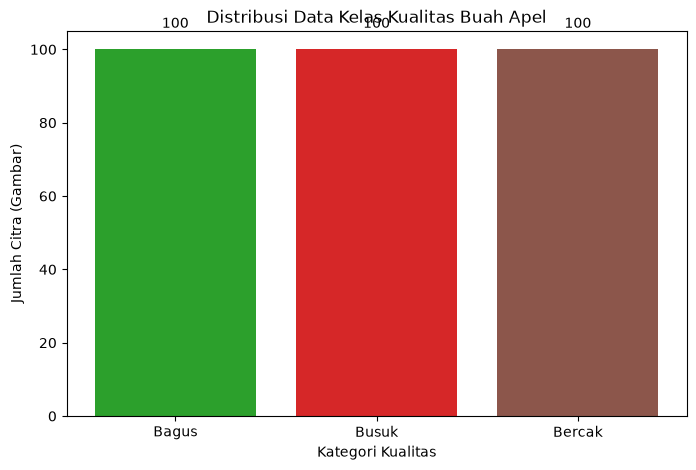

In [1]:
import os
import glob
import matplotlib.pyplot as plt

print("--- FASE 2 CRISP-DM: DATA UNDERSTANDING ---")

# 1. Mendefinisikan path/lokasi folder dataset
dataset_path = 'dataset'
kelas_apel = ['Bagus', 'Busuk', 'Bercak']
jumlah_data = []

# 2. Menghitung jumlah citra pada masing-masing folder kelas
for kelas in kelas_apel:
    folder_path = os.path.join(dataset_path, kelas)
    # Menghitung semua file format apapun di dalam folder kelas tersebut
    gambar = glob.glob(os.path.join(folder_path, '*.*'))
    jumlah_data.append(len(gambar))
    print(f"Jumlah gambar pada kelas {kelas}: {len(gambar)} citra")

# 3. Membuat Visualisasi Grafik Batang (Bar Chart) untuk Slide Progress Report
plt.figure(figsize=(8, 5))
bars = plt.bar(kelas_apel, jumlah_data, color=['#2ca02c', '#d62728', '#8c564b'])

# Menambahkan keterangan angka di atas masing-masing grafik batang
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 5, int(yval), ha='center', va='bottom')

plt.title('Distribusi Data Kelas Kualitas Buah Apel')
plt.xlabel('Kategori Kualitas')
plt.ylabel('Jumlah Citra (Gambar)')
plt.show()

--- FASE 3 CRISP-DM: DATA PREPARATION (MODIFIKASI PROSES) ---


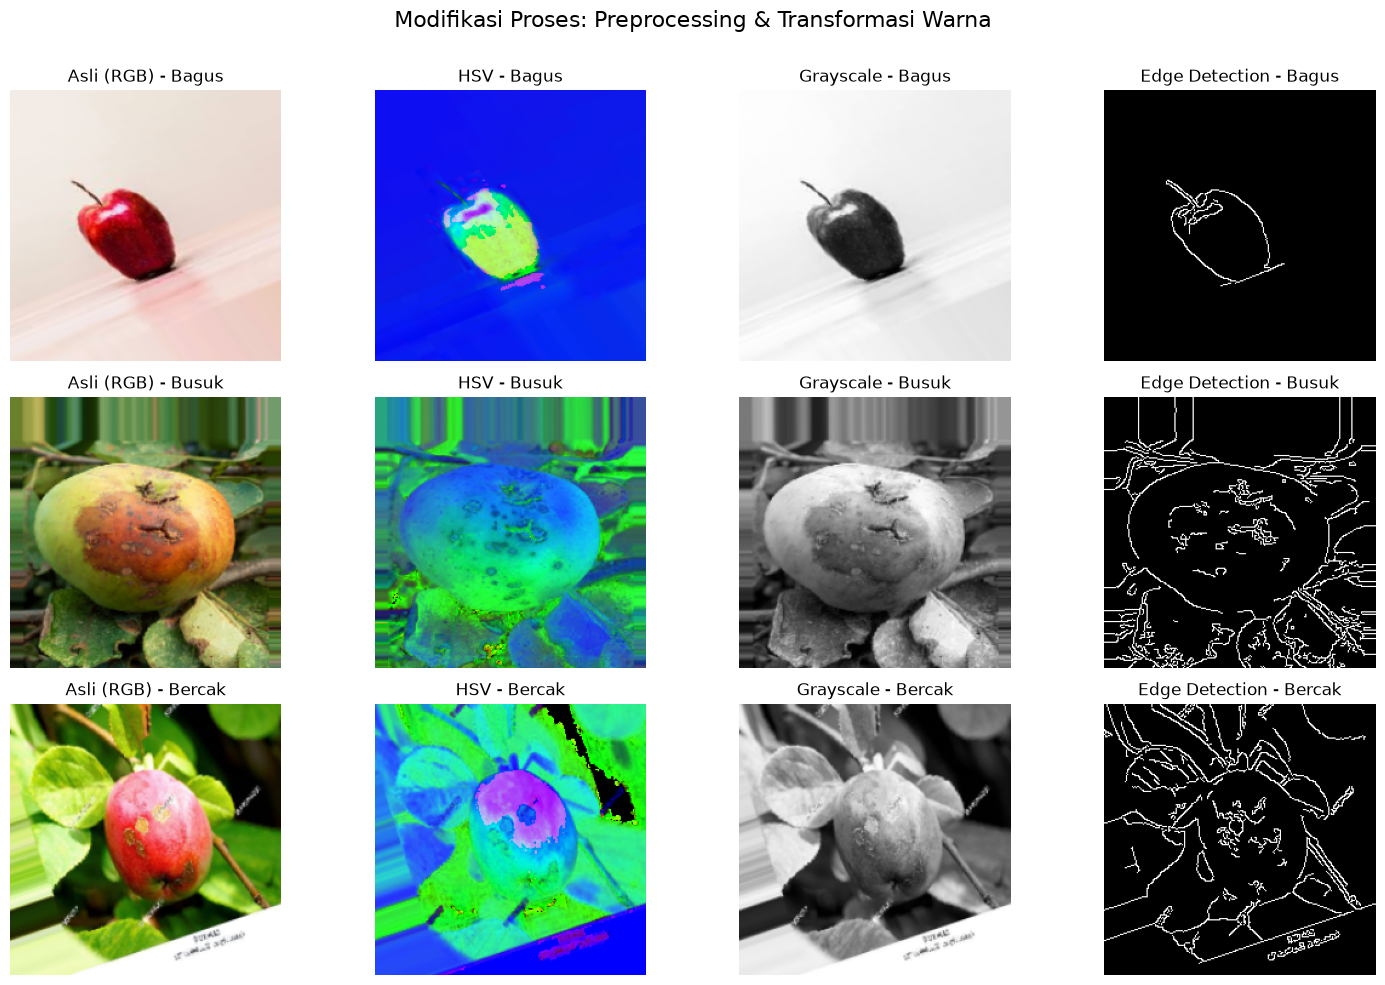

In [3]:
import cv2
import os
import glob
import matplotlib.pyplot as plt

print("--- FASE 3 CRISP-DM: DATA PREPARATION (MODIFIKASI PROSES) ---")

dataset_path = 'dataset'
kelas_apel = ['Bagus', 'Busuk', 'Bercak']
target_size = (224, 224) # Ukuran standar untuk model CNN

# Siapkan figure untuk plot
fig, axes = plt.subplots(3, 4, figsize=(15, 10))
fig.suptitle('Modifikasi Proses: Preprocessing & Transformasi Warna', fontsize=16)

for i, kelas in enumerate(kelas_apel):
    # Ambil 1 sampel gambar pertama dari setiap folder
    folder_path = os.path.join(dataset_path, kelas)
    sample_img_path = glob.glob(os.path.join(folder_path, '*.*'))[0]
    
    # 1. Membaca Gambar (OpenCV membaca dalam format BGR)
    img_bgr = cv2.imread(sample_img_path)
    
    # 2. Resize Gambar (Menyeragamkan ukuran)
    img_resized = cv2.resize(img_bgr, target_size)
    
    # 3. Konversi BGR ke RGB (Untuk ditampilkan visual aslinya)
    img_rgb = cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB)
    
    # 4. MODIFIKASI: Konversi ke HSV (Fokus pada warna/tekstur asli, mengabaikan bayangan/cahaya)
    img_hsv = cv2.cvtColor(img_resized, cv2.COLOR_BGR2HSV)
    
    # 5. MODIFIKASI: Konversi ke Grayscale (Deteksi kerusakan intensitas cahaya)
    img_gray = cv2.cvtColor(img_resized, cv2.COLOR_BGR2GRAY)
    
    # 6. MODIFIKASI: Canny Edge Detection (Deteksi Tepi untuk memperjelas bentuk bercak/busuk)
    edges = cv2.Canny(img_gray, 100, 200)
    
    # Plotting ke Matplotlib
    ax = axes[i]
    
    # Kolom 1: Asli (RGB)
    ax[0].imshow(img_rgb)
    ax[0].set_title(f'Asli (RGB) - {kelas}')
    ax[0].axis('off')
    
    # Kolom 2: HSV
    ax[1].imshow(img_hsv)
    ax[1].set_title(f'HSV - {kelas}')
    ax[1].axis('off')
    
    # Kolom 3: Grayscale
    ax[2].imshow(img_gray, cmap='gray')
    ax[2].set_title(f'Grayscale - {kelas}')
    ax[2].axis('off')
    
    # Kolom 4: Deteksi Tepi (Canny)
    ax[3].imshow(edges, cmap='gray')
    ax[3].set_title(f'Edge Detection - {kelas}')
    ax[3].axis('off')

plt.tight_layout()
plt.subplots_adjust(top=0.9)
plt.show()

In [6]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

print("--- FASE 4 CRISP-DM: SETUP DATA GENERATOR ---")

dataset_path = 'dataset'
IMG_WIDTH, IMG_HEIGHT = 224, 224
BATCH_SIZE = 32

# 1. Modifikasi Proses: Data Augmentation & Normalisasi Piksel (0-1)
datagen = ImageDataGenerator(
    rescale=1./255,           # Normalisasi nilai piksel (wajib untuk CNN)
    rotation_range=20,        # Rotasi gambar acak hingga 20 derajat
    width_shift_range=0.2,    # Geser horizontal
    height_shift_range=0.2,   # Geser vertikal
    zoom_range=0.2,           # Zoom in/out acak
    horizontal_flip=True,     # Balik gambar secara horizontal
    validation_split=0.2      # Membagi 20% data untuk evaluasi (Validation)
)

# 2. Generator Data Latih (Training)
train_generator = datagen.flow_from_directory(
    dataset_path,
    target_size=(IMG_WIDTH, IMG_HEIGHT),
    batch_size=BATCH_SIZE,
    class_mode='categorical', # Karena ada 3 kelas
    subset='training',
    shuffle=True
)

# 3. Generator Data Uji (Validation)
validation_generator = datagen.flow_from_directory(
    dataset_path,
    target_size=(IMG_WIDTH, IMG_HEIGHT),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)

# Cek urutan kelas yang dibaca oleh sistem
print("\nIndeks Kelas:", train_generator.class_indices)

--- FASE 4 CRISP-DM: SETUP DATA GENERATOR ---
Found 240 images belonging to 3 classes.
Found 60 images belonging to 3 classes.

Indeks Kelas: {'Bagus': 0, 'Bercak': 1, 'Busuk': 2}


In [7]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

print("--- FASE 4 CRISP-DM: MEMBANGUN ARSITEKTUR CNN ---")

# Inisialisasi Model Sequential
model = Sequential([
    # Layer Konvolusi 1 (Mendeteksi fitur dasar seperti tepi)
    Conv2D(32, (3, 3), activation='relu', input_shape=(IMG_WIDTH, IMG_HEIGHT, 3)),
    MaxPooling2D(pool_size=(2, 2)),
    
    # Layer Konvolusi 2 (Mendeteksi fitur yang lebih kompleks seperti tekstur)
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),
    
    # Layer Konvolusi 3 (Mendeteksi bagian spesifik seperti bentuk bercak)
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),
    
    # Meratakan matriks menjadi array 1 dimensi
    Flatten(),
    
    # Hidden Layer / Layer Klasifikasi
    Dense(128, activation='relu'),
    Dropout(0.5), # Mencegah overfitting (model terlalu menghafal)
    
    # Output Layer (3 neuron untuk kelas Bagus, Busuk, Bercak)
    Dense(3, activation='softmax') # Softmax mengubah output menjadi persentase probabilitas
])

# Kompilasi model dengan optimizer dan fungsi perhitungan loss
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# Menampilkan ringkasan arsitektur model
model.summary()

--- FASE 4 CRISP-DM: MEMBANGUN ARSITEKTUR CNN ---


c:\Users\ASUS\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,347 (42.61 MB)

 Trainable params: 11,169,347 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
print("--- MEMULAI PROSES TRAINING MODEL ---")

# Menentukan jumlah putaran pembelajaran (Epoch). 
# Kita mulai dengan 10 putaran agar tidak terlalu lama.
EPOCHS = 10 

# Memulai pelatihan dan menyimpan riwayatnya di variabel 'history'
history = model.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=validation_generator,
    verbose=1 # Menampilkan progress bar di layar
)

print("--- TRAINING SELESAI ---")

--- MEMULAI PROSES TRAINING MODEL ---
Epoch 1/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 18s 2s/step - accuracy: 0.3750 - loss: 1.6252 - val_accuracy: 0.3333 - val_loss: 1.0693
Epoch 2/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.4583 - loss: 1.0240 - val_accuracy: 0.5833 - val_loss: 1.0045
Epoch 3/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.5792 - loss: 0.9506 - val_accuracy: 0.5333 - val_loss: 0.9408
Epoch 4/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.5708 - loss: 0.9090 - val_accuracy: 0.5167 - val_loss: 0.9553
Epoch 5/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.5292 - loss: 0.8764 - val_accuracy: 0.5667 - val_loss: 0.9247
Epoch 6/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.6583 - loss: 0.7565 - val_accuracy: 0.5167 - val_loss: 0.9605
Epoch 7/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.5958 - loss: 0.8856 - val_accuracy: 0.5833 - val_loss: 0.8937
Epoch 8/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - accuracy: 0.6667 - loss: 0.8047 - val_accuracy: 0.

--- FASE 5 CRISP-DM: EVALUATION ---


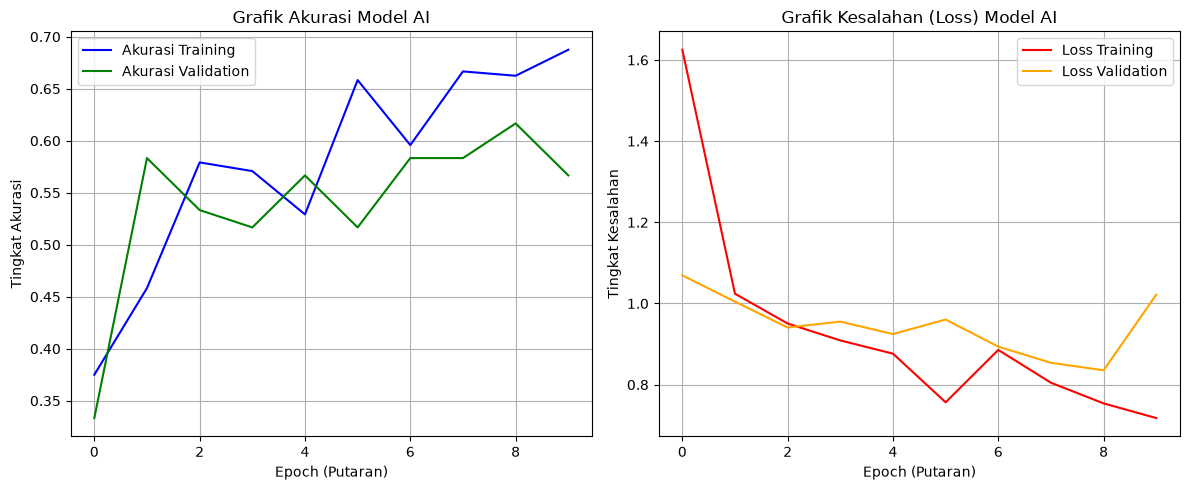

In [11]:
import matplotlib.pyplot as plt

print("--- FASE 5 CRISP-DM: EVALUATION ---")

# Membuat area gambar
plt.figure(figsize=(12, 5))

# 1. Plot Grafik Akurasi (Seberapa pintar AI menebak)
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Akurasi Training', color='blue')
plt.plot(history.history['val_accuracy'], label='Akurasi Validation', color='green')
plt.title('Grafik Akurasi Model AI')
plt.xlabel('Epoch (Putaran)')
plt.ylabel('Tingkat Akurasi')
plt.legend()
plt.grid(True)

# 2. Plot Grafik Loss (Seberapa besar kesalahan AI)
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Loss Training', color='red')
plt.plot(history.history['val_loss'], label='Loss Validation', color='orange')
plt.title('Grafik Kesalahan (Loss) Model AI')
plt.xlabel('Epoch (Putaran)')
plt.ylabel('Tingkat Kesalahan')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [12]:
print("--- FASE 6 CRISP-DM: PENYIMPANAN MODEL ---")

# Menyimpan model yang sudah dilatih
model.save('model_kualitas_apel.h5')

print("Model berhasil disimpan dengan nama 'model_kualitas_apel.h5'")

--- FASE 6 CRISP-DM: PENYIMPANAN MODEL ---
Model berhasil disimpan dengan nama 'model_kualitas_apel.h5'


In [13]:
%pip install streamlit

  Using cached watchdog-6.0.0-py3-none-win_amd64.whl.metadata (44 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached jsonschema_specifications-2025.9.1-py3-none-any.whl.metadata (2.9 kB)
   ---------------------------------------- 0.0/10.4 MB ? eta -:--:--
   ---------------------------------------- 0.1/10.4 MB 3.4 MB/s eta 0:00:04
    --------------------------------------- 0.1/10.4 MB 1.7 MB/s eta 0:00:06
    --------------------------------------- 0.2/10.4 MB 1.9 MB/s eta 0:00:06
   - -------------------------------------- 0.4/10.4 MB 2.0 MB/s eta 0:00:05
   - -------------------------------------- 0.4/10.4 MB 2.1 MB/s eta 0:00:05
   -- ------------------------------------- 0.6/10.4 MB 2.3 MB/s eta 0:00:05
   -- ------------------------------------- 0.8/10.4 MB 2.4 MB/s eta 0:00:05
   --- ------------------------------------ 0.9/10.4 MB 2.5 MB/s eta 0:00:04
   --- ------------------------------------ 1.0/10.4 MB 2.4 MB/s eta 0:00:04
   ---- -----------


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
